In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train = pd.read_csv('/kaggle/input/competitions/playground-series-s6e10/train.csv')
test = pd.read_csv('/kaggle/input/competitions/playground-series-s6e10/test.csv')
sample = pd.read_csv('/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv')

In [3]:
train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [4]:
train.columns

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'satisfaction'],
      dtype='object')

In [5]:
train.isnull().sum()

id                                     0
Age                                    0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             292
Gender                                 0
Customer Type                          0
Type of Travel                         0
Class                                  0
satisfaction                           0
dtype: int64

In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   6996

In [7]:
train['satisfaction'].value_counts()

satisfaction
False    389296
True     310339
Name: count, dtype: int64

<Axes: xlabel='satisfaction', ylabel='count'>

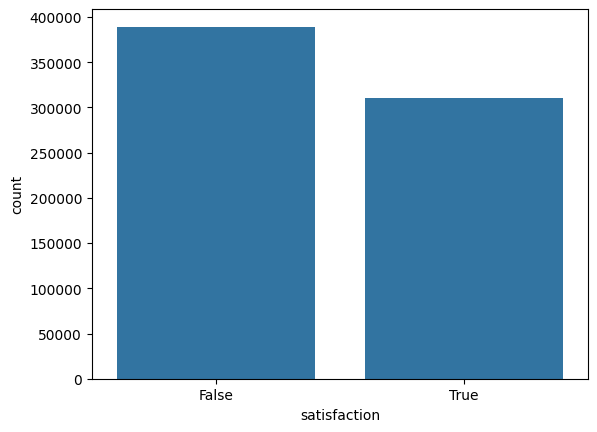

In [8]:
sns.countplot(data = train,x = 'satisfaction')

In [9]:
y = train["satisfaction"].astype(int)   # True/False -> 1/0

## Prepare data
Categories become whole numbers, with the SAME order for train and test. `mask` is built after the columns are final.

In [10]:
cats = ["Gender", "Customer Type", "Type of Travel", "Class"]

def prep(d):
    d = d.drop(columns=[c for c in ["satisfaction", "id"] if c in d]).copy()
    d["Arrival Delay in Minutes"] = d["Arrival Delay in Minutes"].fillna(0)
    for c in cats:
        d[c] = pd.Categorical(d[c], categories=sorted(train[c].unique())).codes
    return d

X = prep(train)
X_test = prep(test)[X.columns]
mask = [c in cats for c in X.columns]

## Train: 5-fold CV with tuned settings
Each fold trains on 80%, scores the other 20%, and predicts the test set. Test predictions are averaged.

In [11]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

params = dict(
    learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=20,
    l2_regularization=60, max_features=0.5,
    early_stopping=True, validation_fraction=0.1, n_iter_no_change=40,
    max_iter=3000, categorical_features=mask,
)

oof = np.zeros(len(X))
test_pred = np.zeros(len(X_test))
for fold, (tr, va) in enumerate(StratifiedKFold(5, shuffle=True, random_state=42).split(X, y)):
    m = HistGradientBoostingClassifier(random_state=fold, **params)
    m.fit(X.iloc[tr], y.iloc[tr])
    oof[va] = m.predict_proba(X.iloc[va])[:, 1]
    test_pred += m.predict_proba(X_test)[:, 1] / 5
    print(f"fold {fold} AUC: {roc_auc_score(y.iloc[va], oof[va]):.5f}")

print("OOF AUC:", roc_auc_score(y, oof))

fold 0 AUC: 0.95900
fold 1 AUC: 0.95756
fold 2 AUC: 0.95962
fold 4 AUC: 0.95900
OOF AUC: 0.958820538719773


## Submission

In [12]:
submission = pd.DataFrame({"id": test["id"], "satisfaction": test_pred})
submission.to_csv("submission.csv", index=False)
print(submission.shape, submission["satisfaction"].min(), submission["satisfaction"].max())
submission.head()

(299844, 2) 0.004323897027184638 0.9908431500479061


,id,satisfaction
0,699635,0.211027
1,699636,0.891975
2,699637,0.908401
3,699638,0.070177
4,699639,0.052537
